<a href="https://colab.research.google.com/github/novaladriann/Kelompok-4_K-Means_IBM-HR-Employee-Attrition/blob/main/IBM_HR_Employee_Attrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1 Proyek Akhir Pembelajaran Mesin — Eksplorasi Data

**Paket 5B-4: IBM HR Employee Attrition**

**Metode kelompok: Klastering (K-Means)**

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
PATH = 'IBM HR Employee Attrition.csv'

# Langkah 1: encoding utf-8-sig karena berkas berawalan BOM (nama kolom pertama bisa terbaca '\ufeffAge')
df = pd.read_csv(PATH, encoding='utf-8-sig', na_values=['?','---','NA','n/a','unknown',' ',''])
print('Berkas   : ', PATH)
print('Bentuk   : ', df.shape)
print('Kolom 1  : ', df.columns[0])

Berkas   :  IBM HR Employee Attrition.csv
Bentuk   :  (1470, 35)
Kolom 1  :  Age


## Langkah 1 — Daftar periksa pemuatan
- [x] `df.shape` = (1470, 35) sesuai tabel paket
- [x] Jumlah kolom > 1 (pemisah koma benar)
- [x] Nama berkas dicatat
- [x] Penanda hilang khas dimasukkan ke `na_values`
- Catatan: BOM di awal berkas ditangani dengan `encoding='utf-8-sig'`.

## Langkah 2 — Potret struktur

In [ ]:
display(df.head(10))
df.info()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
5,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,...,3,80,0,8,2,2,7,7,3,6
6,59,No,Travel_Rarely,1324,Research & Development,3,3,Medical,1,10,...,1,80,3,12,3,2,1,0,0,0
7,30,No,Travel_Rarely,1358,Research & Development,24,1,Life Sciences,1,11,...,2,80,1,1,2,3,1,0,0,0
8,38,No,Travel_Frequently,216,Research & Development,23,3,Life Sciences,1,12,...,2,80,0,10,2,3,9,7,1,8
9,36,No,Travel_Rarely,1299,Research & Development,27,3,Medical,1,13,...,2,80,2,17,3,2,7,7,7,7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [ ]:
display(df.describe().round(2))
display(df.describe(include='object'))

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.00,1470.00,1470.00,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,...,1470.00,1470.0,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00,1470.00
mean,36.92,802.49,9.19,2.91,1.0,1024.87,2.72,65.89,2.73,2.06,...,2.71,80.0,0.79,11.28,2.80,2.76,7.01,4.23,2.19,4.12
std,9.14,403.51,8.11,1.02,0.0,602.02,1.09,20.33,0.71,1.11,...,1.08,0.0,0.85,7.78,1.29,0.71,6.13,3.62,3.22,3.57
min,18.00,102.00,1.00,1.00,1.0,1.00,1.00,30.00,1.00,1.00,...,1.00,80.0,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,30.00,465.00,2.00,2.00,1.0,491.25,2.00,48.00,2.00,1.00,...,2.00,80.0,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00
50%,36.00,802.00,7.00,3.00,1.0,1020.50,3.00,66.00,3.00,2.00,...,3.00,80.0,1.00,10.00,3.00,3.00,5.00,3.00,1.00,3.00
75%,43.00,1157.00,14.00,4.00,1.0,1555.75,4.00,83.75,3.00,3.00,...,4.00,80.0,1.00,15.00,3.00,3.00,9.00,7.00,3.00,7.00
max,60.00,1499.00,29.00,5.00,1.0,2068.00,4.00,100.00,4.00,5.00,...,4.00,80.0,3.00,40.00,6.00,4.00,40.00,18.00,15.00,17.00


,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


**Temuan tipe vs arti:**

Semua kolom bertipe `int64` kecuali 8 kolom teks. Banyak kolom `int64` sebenarnya **kode ordinal** (`Education`, `EnvironmentSatisfaction`, `JobInvolvement`, `JobLevel`, `JobSatisfaction`, `PerformanceRating`, `RelationshipSatisfaction`, `StockOptionLevel`, `WorkLifeBalance`). Tidak ada kolom tanggal.

## Langkah 3 — Pemeriksaan kebersihan (6 pemeriksaan)

### 3a. Nilai Hilang

In [ ]:
hilang = pd.DataFrame({'jumlah': df.isna().sum(), 'persen': (df.isna().mean()*100).round(2)})
print('Total sel hilang: ', df.isna().sum().sum())
print('Kolom dengan nilai hilang:', list(hilang[hilang.jumlah>0].index) or 'tidak ada')
display(hilang)

Total sel hilang:  0
Kolom dengan nilai hilang: tidak ada


,jumlah,persen
Age,0,0.0
Attrition,0,0.0
BusinessTravel,0,0.0
DailyRate,0,0.0
Department,0,0.0
DistanceFromHome,0,0.0
Education,0,0.0
EducationField,0,0.0
EmployeeCount,0,0.0
EmployeeNumber,0,0.0


### 3b. Data hilang tersamar

In [ ]:
# Kolom yang secara logika tidak mungkin nol (harus > 0)
for k in ['Age','DailyRate','HourlyRate','MonthlyIncome','MonthlyRate','JobLevel','Education','StandardHours']:
    print(f'{k:15s} -> nol: {(df[k]==0).sum():3d} | min: {df[k].min()}')
# Kolom yang SAH bernilai nol (bukan data hilang): periksa maknanya
for k in ['NumCompaniesWorked','StockOptionLevel','TrainingTimesLastYear','YearsAtCompany','YearsSinceLastPromotion','TotalWorkingYears']:
    print(f'{k:25s} -> nol: {(df[k]==0).sum():3d} baris (nol sah: mis. karyawan baru / tanpa opsi saham)')
# Nilai unik kolom kategori
for k in df.select_dtypes(exclude='number').columns:
    print(k, '->', sorted(df[k].unique()))

Age             -> nol:   0 | min: 18
DailyRate       -> nol:   0 | min: 102
HourlyRate      -> nol:   0 | min: 30
MonthlyIncome   -> nol:   0 | min: 1009
MonthlyRate     -> nol:   0 | min: 2094
JobLevel        -> nol:   0 | min: 1
Education       -> nol:   0 | min: 1
StandardHours   -> nol:   0 | min: 80
NumCompaniesWorked        -> nol: 197 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
StockOptionLevel          -> nol: 631 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
TrainingTimesLastYear     -> nol:  54 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
YearsAtCompany            -> nol:  44 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
YearsSinceLastPromotion   -> nol: 581 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
TotalWorkingYears         -> nol:  11 baris (nol sah: mis. karyawan baru / tanpa opsi saham)
Attrition -> ['No', 'Yes']
BusinessTravel -> ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department -> ['Human Resources', 'Re

### 3c. Duplikat

In [ ]:
print('Baris identik seluruhnya :', df.duplicated().sum())
print('EmployeeNumber berulang   :', df['EmployeeNumber'].duplicated().sum())

Baris identik seluruhnya : 0
EmployeeNumber berulang   : 0


**Hasil:** tidak ada nol pada kolom yang mustahil nol, tidak ada `unknown`/`?`/spasi pada kolom kategori. Nol pada `NumCompaniesWorked`, `StockOptionLevel`, `TrainingTimesLastYear`, `YearsAtCompany`, dll. adalah **nilai sah**, bukan data hilang tersamar. Pemeriksaan tetap dilaporkan meskipun hasilnya nol.

### 3d. Kolom konstan dan identifier

In [ ]:
n = df.nunique()
print('Kolom konstan        :', list(n[n<=1].index))
print('Hampir unik per baris:', list(n[n>0.9*len(df)].index))
print({k: int(n[k]) for k in ['EmployeeNumber','MonthlyIncome','MonthlyRate']})

Kolom konstan        : ['EmployeeCount', 'Over18', 'StandardHours']
Hampir unik per baris: ['EmployeeNumber', 'MonthlyIncome', 'MonthlyRate']
{'EmployeeNumber': 1470, 'MonthlyIncome': 1349, 'MonthlyRate': 1427}


**Temuan:**
- Konstan: `EmployeeCount` (=1), `StandardHours` (=80), `Over18` (='Y') → **dibuang**.
- `EmployeeNumber` unik 100% → **identifier**, dibuang dari fitur (disimpan hanya untuk penelusuran).
- `MonthlyIncome` dan `MonthlyRate` muncul di daftar "hampir unik" **hanya karena kontinu**, bukan identifier. Keduanya tetap kandidat fitur. *(Catatan: `MonthlyRate` tidak berkorelasi dengan `MonthlyIncome`;

### 3e. Nilai mustahil dan pencilan (per kolom, bukan otomatis)

In [ ]:
# Konsistensi logika antar kolom (nilai mustahil)
print('YearsAtCompany > TotalWorkingYears       :', (df.YearsAtCompany > df.TotalWorkingYears).sum())
print('YearsInCurrentRole > YearsAtCompany      :', (df.YearsInCurrentRole > df.YearsAtCompany).sum())
print('YearsWithCurrManager > YearsAtCompany    :', (df.YearsWithCurrManager > df.YearsAtCompany).sum())
print('YearsSinceLastPromotion > YearsAtCompany :', (df.YearsSinceLastPromotion > df.YearsAtCompany).sum())
print('Usia mulai kerja < 14 (Age-TotalWorkingYears):', ((df.Age - df.TotalWorkingYears) < 14).sum())
print('Rentang Age:', df.Age.min(), '-', df.Age.max())

# Pencilan IQR dilaporkan per kolom, hanya untuk fitur segmentasi kandidat
cand = ['Age','MonthlyIncome','TotalWorkingYears','YearsAtCompany','YearsSinceLastPromotion','NumCompaniesWorked','DistanceFromHome','PercentSalaryHike','TrainingTimesLastYear']
rows=[]
for k in cand:
    q1,q3 = df[k].quantile([.25,.75]); i=q3-q1
    out = ((df[k]<q1-1.5*i)|(df[k]>q3+1.5*i)).sum()
    rows.append([k, df[k].min(), df[k].max(), out, round(out/len(df)*100,1), round(df[k].skew(),2)])
outl = pd.DataFrame(rows, columns=['kolom','min','max','di_luar_pagar','persen','skewness']); outl

YearsAtCompany > TotalWorkingYears       : 0
YearsInCurrentRole > YearsAtCompany      : 0
YearsWithCurrManager > YearsAtCompany    : 0
YearsSinceLastPromotion > YearsAtCompany : 0
Usia mulai kerja < 14 (Age-TotalWorkingYears): 0
Rentang Age: 18 - 60


,kolom,min,max,di_luar_pagar,persen,skewness
0,Age,18,60,0,0.0,0.41
1,MonthlyIncome,1009,19999,114,7.8,1.37
2,TotalWorkingYears,0,40,63,4.3,1.12
3,YearsAtCompany,0,40,104,7.1,1.76
4,YearsSinceLastPromotion,0,15,107,7.3,1.98
5,NumCompaniesWorked,0,9,52,3.5,1.03
6,DistanceFromHome,1,29,0,0.0,0.96
7,PercentSalaryHike,11,25,0,0.0,0.82
8,TrainingTimesLastYear,0,6,238,16.2,0.55


**Hasil:** tidak ada spasi berlebih maupun ejaan ganda pada label kategori; tidak ada penyeragaman yang diperlukan.

## Langkah 4 — Cabang C (Klastering): menyiapkan ruang fitur
Tidak ada variabel target. `Attrition` **tidak dipakai sebagai fitur**; ia disimpan sebagai *bahan penafsiran* klaster (setelah klaster terbentuk, kita lihat apakah ada klaster dengan tingkat keluar lebih tinggi). Jumlah klaster **belum ditetapkan** pada tahap ini (Tahap 2: Elbow/Silhouette).

**Usulan fitur segmentasi "profil karyawan"** (alasan: menggambarkan senioritas, kompensasi, mobilitas, dan pengalaman kerja):

In [ ]:
fitur_num = ['Age','MonthlyIncome','TotalWorkingYears','YearsAtCompany','YearsSinceLastPromotion',
             'NumCompaniesWorked','DistanceFromHome',
             'JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance','JobInvolvement']
fitur_bin = ['OverTime']        # Yes/No -> 0/1 (penyederhanaan; Langkah 4 poin kategori)
bahan_tafsir = ['Attrition','JobRole','Department','JobLevel','Gender','MaritalStatus']   # BUKAN fitur

X = df[fitur_num].copy()
X['OverTime_Yes'] = (df['OverTime']=='Yes').astype(int)
print('Jumlah fitur segmentasi:', X.shape[1])
display(X.describe().T.round(2))

Jumlah fitur segmentasi: 12


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.0,36.0,43.0,60.0
MonthlyIncome,1470.0,6502.93,4707.96,1009.0,2911.0,4919.0,8379.0,19999.0
TotalWorkingYears,1470.0,11.28,7.78,0.0,6.0,10.0,15.0,40.0
YearsAtCompany,1470.0,7.01,6.13,0.0,3.0,5.0,9.0,40.0
YearsSinceLastPromotion,1470.0,2.19,3.22,0.0,0.0,1.0,3.0,15.0
NumCompaniesWorked,1470.0,2.69,2.50,0.0,1.0,2.0,4.0,9.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.0,7.0,14.0,29.0
JobSatisfaction,1470.0,2.73,1.10,1.0,2.0,3.0,4.0,4.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.0,3.0,4.0,4.0
WorkLifeBalance,1470.0,2.76,0.71,1.0,2.0,3.0,3.0,4.0


**Alasan pemilihan & yang sengaja dikeluarkan**
- `JobLevel` dikeluarkan karena korelasinya dengan `MonthlyIncome` ≈ 0,95 (hampir mengukur hal yang sama; akan memberi bobot ganda pada dimensi "jenjang/gaji"). Dipakai sebagai bahan penafsiran.
- `YearsInCurrentRole` dan `YearsWithCurrManager` dikeluarkan karena berkorelasi 0,7–0,77 dengan `YearsAtCompany` (lihat heatmap).
- `PercentSalaryHike` & `PerformanceRating` dikeluarkan (berkorelasi 0,77; juga kurang bermakna untuk profil). `DailyRate`, `HourlyRate`, `MonthlyRate`: artinya tidak jelas pada sumber → belum boleh masuk model (Aturan Langkah 0).
- Skor ordinal 1–4 dipakai sebagai numerik: **penyederhanaan** yang harus disebut di laporan.


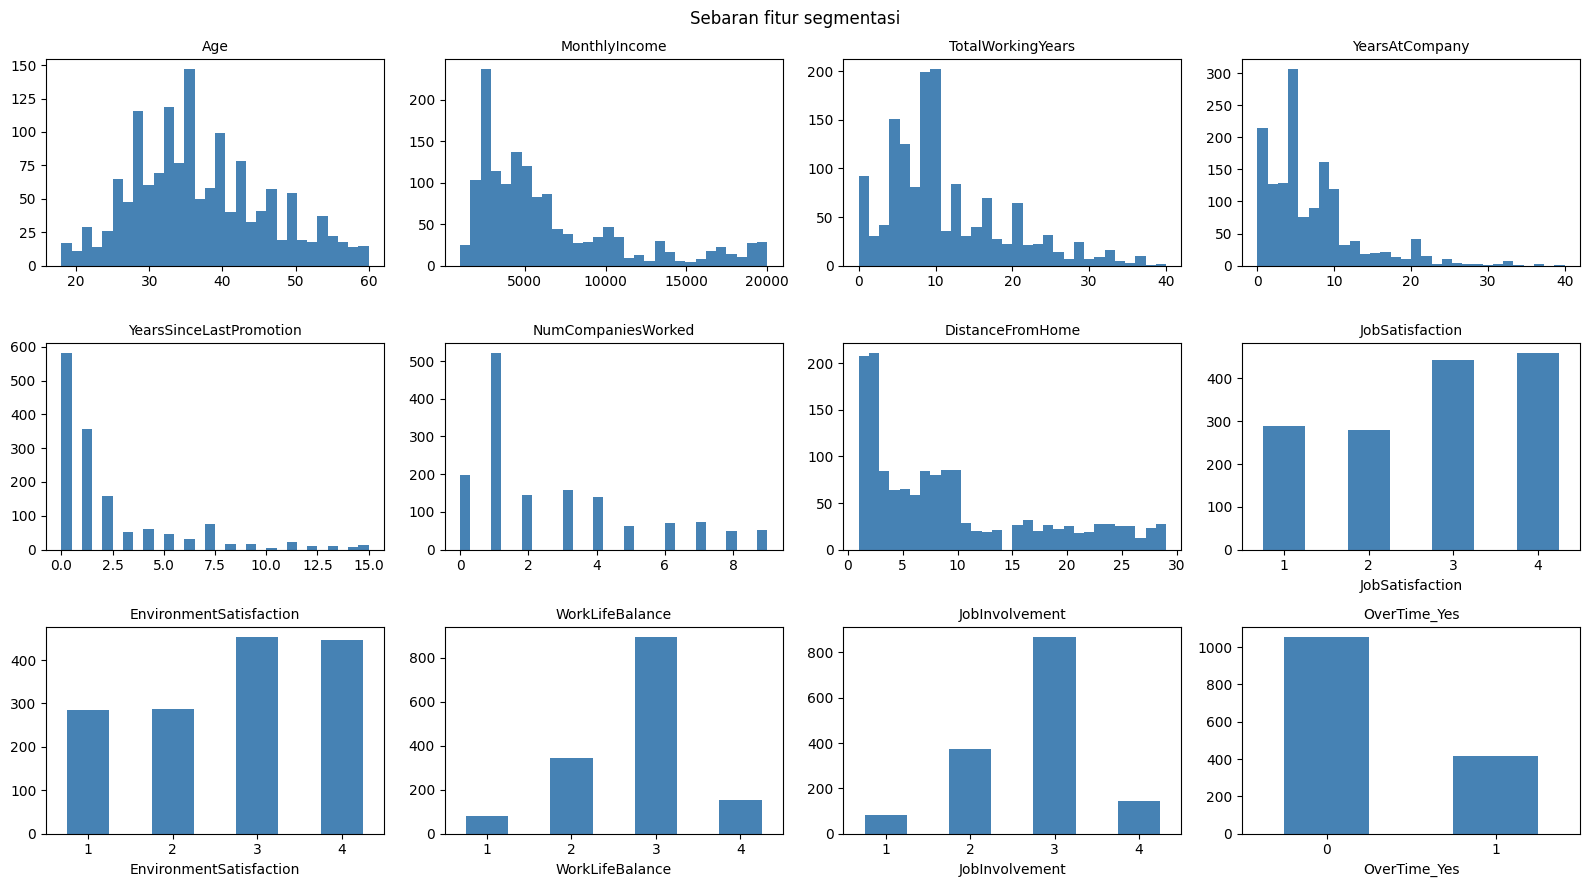

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, k in zip(axes.ravel(), X.columns):
    if X[k].nunique() <= 5: X[k].value_counts().sort_index().plot.bar(ax=ax, color='steelblue', rot=0)
    else: ax.hist(X[k], bins=30, color='steelblue')
    ax.set_title(k, fontsize=10)
plt.suptitle('Sebaran fitur segmentasi'); plt.tight_layout(); plt.show()

Interpretasi: MonthlyIncome, YearsAtCompany, YearsSinceLastPromotion, dan TotalWorkingYears menceng ke kanan (ekor panjang pada senior); skor kepuasan menumpuk di nilai 3–4; OverTime_Yes sekitar 28% karyawan. Sebaran menceng berarti K-Means rentan tertarik oleh ekor.



### 4b. Pencilan fitur segmentasi

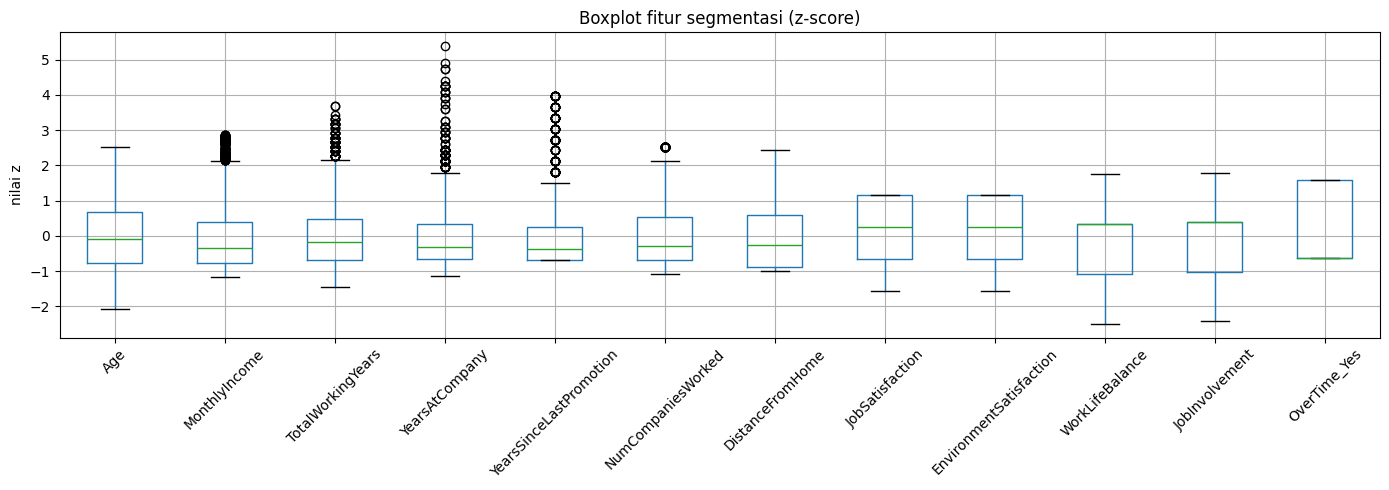

In [ ]:
Z = (X - X.mean())/X.std()
plt.figure(figsize=(14,5)); Z.boxplot(rot=45); plt.ylabel('nilai z'); plt.title('Boxplot fitur segmentasi (z-score)'); plt.tight_layout(); plt.show()

Interpretasi: titik di atas pagar terkonsentrasi pada fitur yang menceng ke kanan (MonthlyIncome, YearsAtCompany, YearsSinceLastPromotion, TotalWorkingYears). Ini karyawan senior nyata, bukan kesalahan data; risikonya: satu klaster kecil berisi pencilan.



### 4c. Kebutuhan penskalaan

In [ ]:
rentang = pd.DataFrame({'min':X.min(),'max':X.max(),'std':X.std().round(2)}).sort_values('std', ascending=False)
display(rentang)
print('Rasio std terbesar/terkecil: %.0fx' % (rentang['std'].max()/rentang['std'].min()))

,min,max,std
MonthlyIncome,1009,19999,4707.96
Age,18,60,9.14
DistanceFromHome,1,29,8.11
TotalWorkingYears,0,40,7.78
YearsAtCompany,0,40,6.13
YearsSinceLastPromotion,0,15,3.22
NumCompaniesWorked,0,9,2.50
JobSatisfaction,1,4,1.10
EnvironmentSatisfaction,1,4,1.09
WorkLifeBalance,1,4,0.71


Rasio std terbesar/terkecil: 10462x


**Pernyataan:** `MonthlyIncome` (std ≈ ribuan) akan mendominasi jarak Euclidean atas fitur berskala 1–4 jika tidak diskalakan. **Penskalaan wajib** (StandardScaler). Dilakukan di Tahap 2 di dalam `Pipeline`, bukan pada dataset bersih Tahap 1.

## Langkah 5 — Hubungan antar variabel, multikolinearitas, dan kebocoran

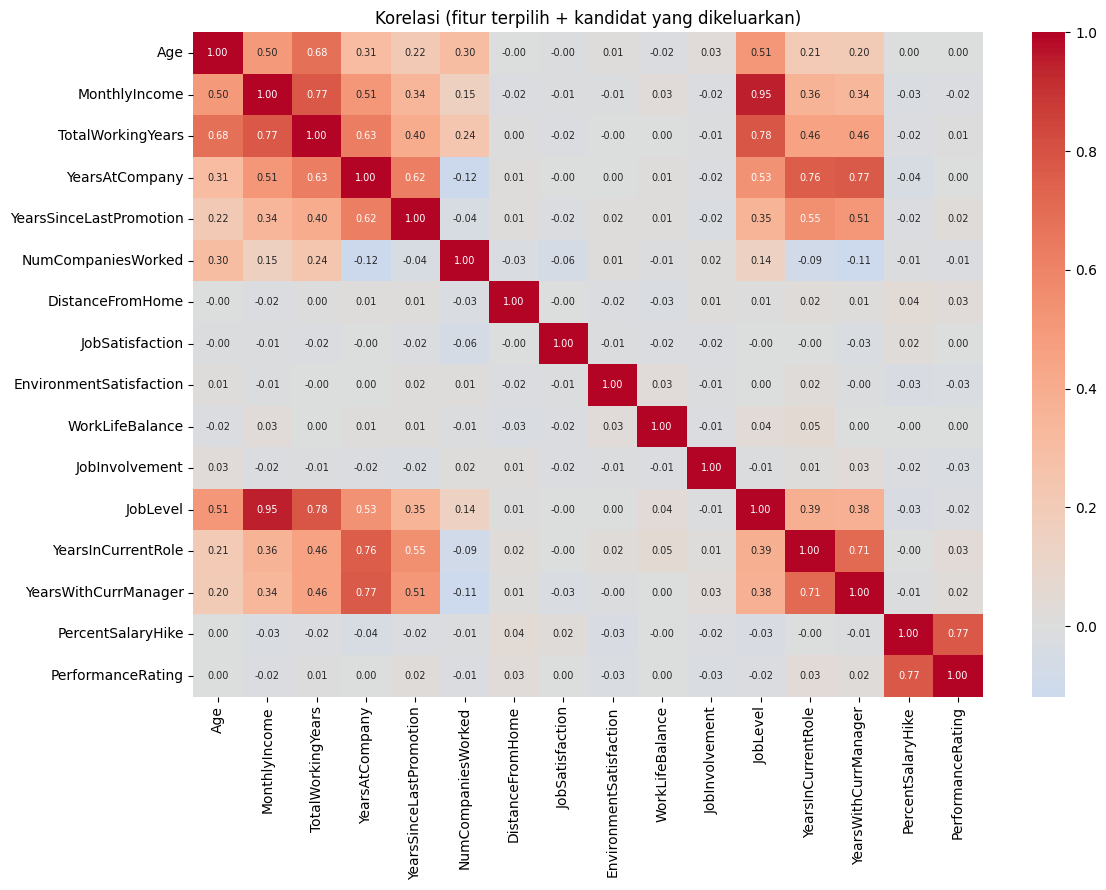

Pasangan |r| > 0,7:
MonthlyIncome       JobLevel                0.950
TotalWorkingYears   JobLevel                0.782
PercentSalaryHike   PerformanceRating       0.774
MonthlyIncome       TotalWorkingYears       0.773
YearsAtCompany      YearsWithCurrManager    0.769
                    YearsInCurrentRole      0.759
YearsInCurrentRole  YearsWithCurrManager    0.714
dtype: float64

Pasangan |r| > 0,8 pada fitur segmentasi terpilih: tidak ada


In [ ]:
kor = df[fitur_num + ['JobLevel','YearsInCurrentRole','YearsWithCurrManager','PercentSalaryHike','PerformanceRating']].corr()
plt.figure(figsize=(12,9)); sns.heatmap(kor, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size':7}); plt.title('Korelasi (fitur terpilih + kandidat yang dikeluarkan)'); plt.tight_layout(); plt.show()
k2 = kor.abs().where(np.triu(np.ones(kor.shape),1).astype(bool)).stack()
print('Pasangan |r| > 0,7:'); print(k2[k2>0.7].sort_values(ascending=False).round(3))
print('\nPasangan |r| > 0,8 pada fitur segmentasi terpilih:',
      list(k2[(k2>0.8)&k2.index.get_level_values(0).isin(X.columns)&k2.index.get_level_values(1).isin(X.columns)].index) or 'tidak ada')

**Interpretasi:** pasangan terkuat: `JobLevel`–`MonthlyIncome` (≈0,95), `JobLevel`–`TotalWorkingYears` (≈0,78), `MonthlyIncome`–`TotalWorkingYears` (≈0,77), `PercentSalaryHike`–`PerformanceRating` (≈0,77), `YearsAtCompany` dengan `YearsInCurrentRole`/`YearsWithCurrManager` (≈0,76–0,77). Pada fitur segmentasi terpilih **tidak ada pasangan > 0,8**, tetapi `MonthlyIncome`, `TotalWorkingYears`, dan `Age` saling terkait sehingga dimensi "senioritas" akan berbobot lebih besar dalam jarak.

**Pemeriksaan kebocoran:** pada klastering tidak ada target, sehingga kebocoran bentuk definisional/pengganti terhadap target tidak berlaku. Satu-satunya risiko: memasukkan `Attrition` sebagai fitur (akan membuat klaster "memisahkan" yang keluar dan yang tetap secara artifisial). **Keputusan: `Attrition` dikeluarkan dari fitur dan hanya dipakai untuk menafsirkan klaster.** Hasil pemeriksaan: tidak ditemukan kebocoran pada fitur terpilih.

### Distribusi `Attrition` (bahan penafsiran)

Attrition
No     1233
Yes     237
Name: count, dtype: int64
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


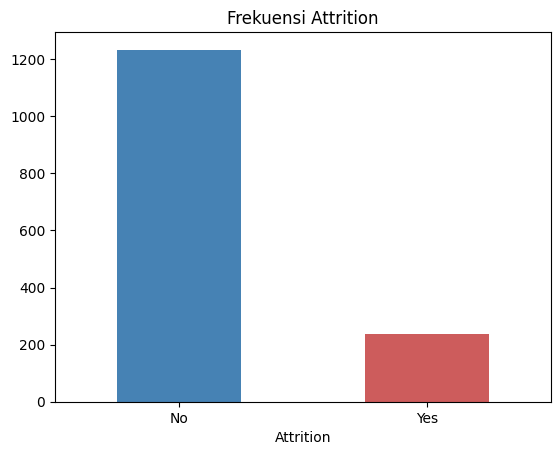

In [ ]:
vc = df.Attrition.value_counts(); print(vc); print((df.Attrition.value_counts(normalize=True)*100).round(2))
vc.plot.bar(color=['steelblue','indianred'], rot=0); plt.title('Frekuensi Attrition'); plt.show()

**Interpretasi:** sekitar 16% karyawan keluar (kelas tidak seimbang). Karena ini klastering, tidak ada akurasi/garis dasar; angka ini dipakai nanti untuk membandingkan tingkat keluar per klaster dengan rata-rata keseluruhan.

## Langkah 7 — Keputusan, kamus data, dan penyimpanan data bersih

In [ ]:
dibuang = ['EmployeeCount','StandardHours','Over18']
df_bersih = df.drop(columns=dibuang).copy()
# tipe: kolom teks -> kategori; kode ordinal tetap angka (dicatat di kamus)
for k in df_bersih.select_dtypes(exclude='number').columns: df_bersih[k] = df_bersih[k].astype('category')
df_bersih['OverTime_Yes'] = (df_bersih['OverTime']=='Yes').astype(int)

keputusan = pd.DataFrame([
 ['EmployeeCount, StandardHours, Over18','Bernilai sama untuk 1.470 baris (1, 80, Y)','Dibuang (3 kolom)','Konstan, tidak membawa informasi','0 baris, 3 kolom'],
 ['EmployeeNumber','Unik per baris (1.470 nilai unik)','Disimpan hanya untuk penelusuran; bukan fitur','Identifier merusak model jika jadi fitur','0 baris'],
 ['Nilai hilang','0 sel hilang; tidak ada nol mustahil / label unknown','Tidak ada imputasi','Pemeriksaan dilaporkan meski nol','0 baris'],
 ['Duplikat','0 baris identik; 0 EmployeeNumber berulang','Tidak ada yang dibuang','Tidak ada duplikat','0 baris'],
 ['MonthlyIncome, YearsAtCompany, YearsSinceLastPromotion, dll.','Pencilan IQR sekitar 3–8% pada beberapa kolom (tertinggi MonthlyIncome ≈7,8%); tidak ada nilai mustahil','Dipertahankan; penanganan (mis. log) diputuskan di Tahap 2','Nilai nyata, bukan kesalahan; membuang mengubah pertanyaan','0 baris'],
 ['JobLevel vs MonthlyIncome','r ≈ 0,95','JobLevel tidak jadi fitur segmentasi (dipakai untuk penafsiran)','Multikolinearitas; menghindari bobot ganda','0 baris, 1 kolom dari fitur'],
 ['YearsInCurrentRole, YearsWithCurrManager','r 0,71–0,77 dengan YearsAtCompany','Tidak jadi fitur segmentasi','Redundan dengan YearsAtCompany','0 baris, 2 kolom dari fitur'],
 ['Attrition','Kategori Yes/No (≈16% Yes)','Tidak jadi fitur; bahan penafsiran klaster','Menghindari kebocoran pada klaster','0 baris'],
 ['OverTime','Teks Yes/No','Dikodekan 0/1 → OverTime_Yes','K-Means butuh numerik; penyederhanaan','1.470 baris (kolom baru)'],
 ['Skor ordinal 1–4','Tipe int64','Diperlakukan numerik, dinyatakan sebagai penyederhanaan','Jarak antar level dianggap sama','—'],
], columns=['Kolom / baris','Temuan','Keputusan','Alasan','Baris terpengaruh'])
display(keputusan)
print('ukuran awal :', df.shape); print('ukuran bersih:', df_bersih.shape)
df_bersih.to_csv('data_bersih.csv', index=False)
print('Tersimpan: data_bersih.csv')

,Kolom / baris,Temuan,Keputusan,Alasan,Baris terpengaruh
0,"EmployeeCount, StandardHours, Over18","Bernilai sama untuk 1.470 baris (1, 80, Y)",Dibuang (3 kolom),"Konstan, tidak membawa informasi","0 baris, 3 kolom"
1,EmployeeNumber,Unik per baris (1.470 nilai unik),Disimpan hanya untuk penelusuran; bukan fitur,Identifier merusak model jika jadi fitur,0 baris
2,Nilai hilang,0 sel hilang; tidak ada nol mustahil / label u...,Tidak ada imputasi,Pemeriksaan dilaporkan meski nol,0 baris
3,Duplikat,0 baris identik; 0 EmployeeNumber berulang,Tidak ada yang dibuang,Tidak ada duplikat,0 baris
4,"MonthlyIncome, YearsAtCompany, YearsSinceLastP...",Pencilan IQR sekitar 3–8% pada beberapa kolom ...,Dipertahankan; penanganan (mis. log) diputuska...,"Nilai nyata, bukan kesalahan; membuang menguba...",0 baris
5,JobLevel vs MonthlyIncome,"r ≈ 0,95",JobLevel tidak jadi fitur segmentasi (dipakai ...,Multikolinearitas; menghindari bobot ganda,"0 baris, 1 kolom dari fitur"
6,"YearsInCurrentRole, YearsWithCurrManager","r 0,71–0,77 dengan YearsAtCompany",Tidak jadi fitur segmentasi,Redundan dengan YearsAtCompany,"0 baris, 2 kolom dari fitur"
7,Attrition,Kategori Yes/No (≈16% Yes),Tidak jadi fitur; bahan penafsiran klaster,Menghindari kebocoran pada klaster,0 baris
8,OverTime,Teks Yes/No,Dikodekan 0/1 → OverTime_Yes,K-Means butuh numerik; penyederhanaan,1.470 baris (kolom baru)
9,Skor ordinal 1–4,Tipe int64,"Diperlakukan numerik, dinyatakan sebagai penye...",Jarak antar level dianggap sama,—


ukuran awal : (1470, 35)
ukuran bersih: (1470, 33)
Tersimpan: data_bersih.csv


In [ ]:
# Kamus data (Lampiran A) — isi lengkap seluruh kolom bersih
K = {
'Age':('Usia karyawan','tahun','numerik bulat','fitur'),
'Attrition':('Apakah karyawan keluar (Yes/No)','-','kategori','bahan penafsiran'),
'BusinessTravel':('Frekuensi perjalanan dinas','-','kategori','bahan penafsiran'),
'DailyRate':('Tarif harian (arti tepat belum jelas di sumber)','-','numerik','dibuang dari fitur'),
'Department':('Departemen','-','kategori','bahan penafsiran'),
'DistanceFromHome':('Jarak rumah ke kantor','satuan sumber (mil/km: cek sumber)','numerik bulat','fitur'),
'Education':('Jenjang pendidikan (1–5)','kode ordinal','ordinal','bahan penafsiran'),
'EducationField':('Bidang pendidikan','-','kategori','bahan penafsiran'),
'EmployeeNumber':('Nomor karyawan','-','identifier','identifier'),
'EnvironmentSatisfaction':('Kepuasan lingkungan kerja (1–4)','skor','ordinal','fitur'),
'Gender':('Jenis kelamin','-','kategori','bahan penafsiran'),
'HourlyRate':('Tarif per jam (arti belum jelas)','-','numerik','dibuang dari fitur'),
'JobInvolvement':('Keterlibatan kerja (1–4)','skor','ordinal','fitur'),
'JobLevel':('Jenjang jabatan (1–5)','kode ordinal','ordinal','bahan penafsiran'),
'JobRole':('Peran pekerjaan','-','kategori','bahan penafsiran'),
'JobSatisfaction':('Kepuasan kerja (1–4)','skor','ordinal','fitur'),
'MaritalStatus':('Status pernikahan','-','kategori','bahan penafsiran'),
'MonthlyIncome':('Pendapatan bulanan','mata uang sumber','numerik bulat','fitur'),
'MonthlyRate':('Arti tidak jelas di sumber','-','numerik','dibuang dari fitur'),
'NumCompaniesWorked':('Jumlah perusahaan tempat bekerja sebelumnya','buah','numerik bulat','fitur'),
'OverTime':('Lembur (Yes/No)','-','kategori biner','sumber OverTime_Yes'),
'PercentSalaryHike':('Persentase kenaikan gaji terakhir','%','numerik bulat','dibuang dari fitur (r 0,77 dg PerformanceRating)'),
'PerformanceRating':('Penilaian kinerja (3–4)','kode ordinal','ordinal','dibuang dari fitur'),
'RelationshipSatisfaction':('Kepuasan hubungan kerja (1–4)','skor','ordinal','tidak dipakai'),
'StockOptionLevel':('Level opsi saham (0–3)','kode ordinal','ordinal','tidak dipakai'),
'TotalWorkingYears':('Total lama bekerja','tahun','numerik bulat','fitur'),
'TrainingTimesLastYear':('Frekuensi pelatihan tahun lalu','kali','numerik bulat','tidak dipakai'),
'WorkLifeBalance':('Keseimbangan kerja-hidup (1–4)','skor','ordinal','fitur'),
'YearsAtCompany':('Lama bekerja di perusahaan','tahun','numerik bulat','fitur'),
'YearsInCurrentRole':('Lama di peran saat ini','tahun','numerik bulat','dibuang dari fitur (redundan)'),
'YearsSinceLastPromotion':('Lama sejak promosi terakhir','tahun','numerik bulat','fitur'),
'YearsWithCurrManager':('Lama dengan manajer saat ini','tahun','numerik bulat','dibuang dari fitur (redundan)'),
'OverTime_Yes':('Penanda lembur 1=ya, 0=tidak','-','biner','fitur'),
}
kamus = pd.DataFrame([[k,*v,'tidak ada nilai hilang'] for k,v in K.items()],
        columns=['Nama kolom','Arti','Satuan','Tipe ditetapkan','Peran','Catatan mutu'])
assert set(K)==set(df_bersih.columns), set(df_bersih.columns)^set(K)
kamus.to_csv('kamus_data.csv', index=False); kamus

,Nama kolom,Arti,Satuan,Tipe ditetapkan,Peran,Catatan mutu
0,Age,Usia karyawan,tahun,numerik bulat,fitur,tidak ada nilai hilang
1,Attrition,Apakah karyawan keluar (Yes/No),-,kategori,bahan penafsiran,tidak ada nilai hilang
2,BusinessTravel,Frekuensi perjalanan dinas,-,kategori,bahan penafsiran,tidak ada nilai hilang
3,DailyRate,Tarif harian (arti tepat belum jelas di sumber),-,numerik,dibuang dari fitur,tidak ada nilai hilang
4,Department,Departemen,-,kategori,bahan penafsiran,tidak ada nilai hilang
5,DistanceFromHome,Jarak rumah ke kantor,satuan sumber (mil/km: cek sumber),numerik bulat,fitur,tidak ada nilai hilang
6,Education,Jenjang pendidikan (1–5),kode ordinal,ordinal,bahan penafsiran,tidak ada nilai hilang
7,EducationField,Bidang pendidikan,-,kategori,bahan penafsiran,tidak ada nilai hilang
8,EmployeeNumber,Nomor karyawan,-,identifier,identifier,tidak ada nilai hilang
9,EnvironmentSatisfaction,Kepuasan lingkungan kerja (1–4),skor,ordinal,fitur,tidak ada nilai hilang


## Keterbatasan dan rencana Tahap 2
- Data **sintetis** buatan IBM: pola lebih rapi dari data personalia nyata; klaster tidak boleh ditafsirkan sebagai kondisi nyata tenaga kerja.
- Skor ordinal diperlakukan numerik (penyederhanaan); `OverTime` dikodekan 0/1.
- Tidak ada dimensi waktu; tidak ada alasan keluar. Data tidak menjelaskan *mengapa* karyawan keluar.
- **Tahap 2:** skala (StandardScaler dalam `Pipeline`), tentukan K (Elbow + Silhouette), pertimbangkan transformasi log untuk fitur yang menceng, periksa klaster kecil akibat pencilan, tafsirkan klaster dengan `Attrition`, `JobRole`, `JobLevel`.